# Laboratory 4: Sampling, Quantization, and Frequency Transforms

### Problem 1: Image Sampling and Quantization

1. Digitization Pipeline: Implement a function to simulate the sampling (spatial) and quantization (amplitude) process. 
The user should be able to specify the sampling interval and the number of quantization levels (L).

In [104]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = './mountains.jpg'

In [49]:
s_interval = int(input('Sampling Interval: '))
q_levels = int(input('Quantization Levels: '))

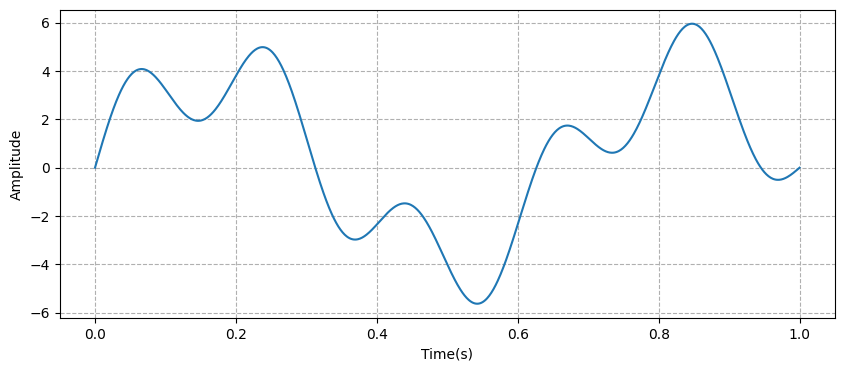

In [41]:
f = 5
fs = 1000
duration = 1
t = np.linspace(0, duration, fs)
analog_img = 2 * np.sin(2 * np.pi * f * t) + 4 * np.sin(2 * np.pi * f * t * 0.3)
plt.figure(figsize = (10, 4)) 
plt.plot(t, analog_img, label = 'Wave Signal')
plt.xlabel('Time(s)')
plt.ylabel('Amplitude')
plt.grid(True, linestyle = '--')
plt.show()

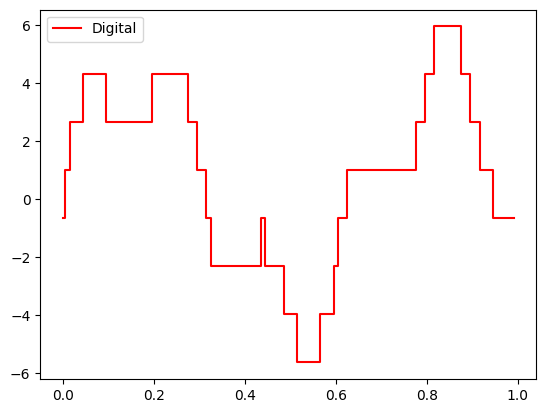

In [ ]:
sampled_t = t[::s_interval]
sampled_s = analog_img[::s_interval]

s_min, s_max = sampled_s.min(), sampled_s.max()
levels = np.linspace(s_min, s_max, q_levels)

quantized_s = np.array([levels[np.abs(levels - val).argmin()] for val in sampled_s])

plt.step(sampled_t, quantized_s, where='mid', color='red', label='Digital')
plt.legend()
plt.show()

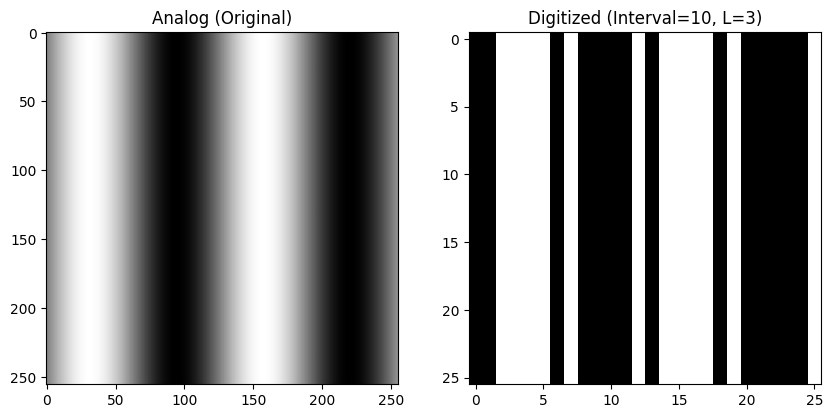

In [102]:
import numpy as np
import matplotlib.pyplot as plt

def digitize_image(img, interval, L):
    sampled = img[::interval, ::interval]
    
    quantized = np.round(sampled * (L - 1) / 255) * (255 / (L - 1))
    return quantized.astype(np.uint8)

x = np.linspace(0, 255, 256)
y = np.linspace(0, 255, 256)
X, Y = np.meshgrid(x, y)
analog_img = (np.sin(X/20) * 127 + 128).astype(np.uint8)

interval = int(input('Enter interval:'))
L = int(input('Enter Levels:'))
digital_img = digitize_image(analog_img, interval, L)

plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(analog_img, cmap='gray')
plt.title("Analog (Original)")

plt.subplot(1, 2, 2)
plt.imshow(digital_img, cmap='gray', interpolation='nearest') 
plt.title(f"Digitized (Interval={interval}, L={L})")

plt.show()


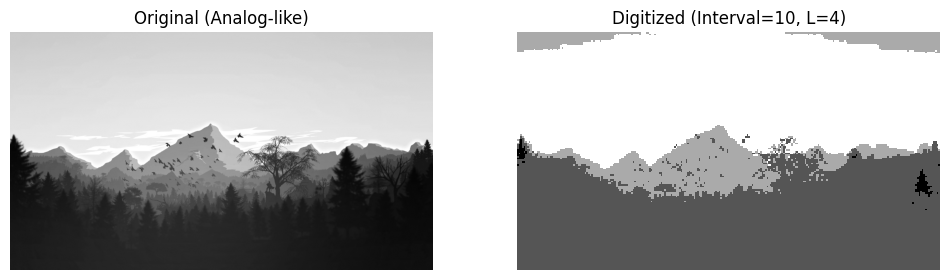

In [ ]:
def digitize_pipeline(img, interval, L):
    sampled = img[::interval, ::interval]
    bins = np.linspace(0, 255, L)
    quantized = np.array([bins[np.abs(bins - val).argmin()] for val in sampled.ravel()])
    quantized = quantized.reshape(sampled.shape).astype(np.uint8)
    return quantized

analog_img = cv2.imread(img, cv2.IMREAD_GRAYSCALE)

digital_img = digitize_pipeline(analog_img, interval=10, L=4)

plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(analog_img, cmap='gray')
plt.title("Original (Analog-like)")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(digital_img, cmap='gray', interpolation='nearest')
plt.title(f"Digitized (Interval=10, L=4)")
plt.axis('off')

plt.show()

2. Statistical Analysis: Generate and display the intensity histograms for:

• The original input image.

• The quantized image at low bit-depths (e.g., 2-bit or 3-bit).

Analyze how quantization ”bins” the histogram and affects the mean intensity.

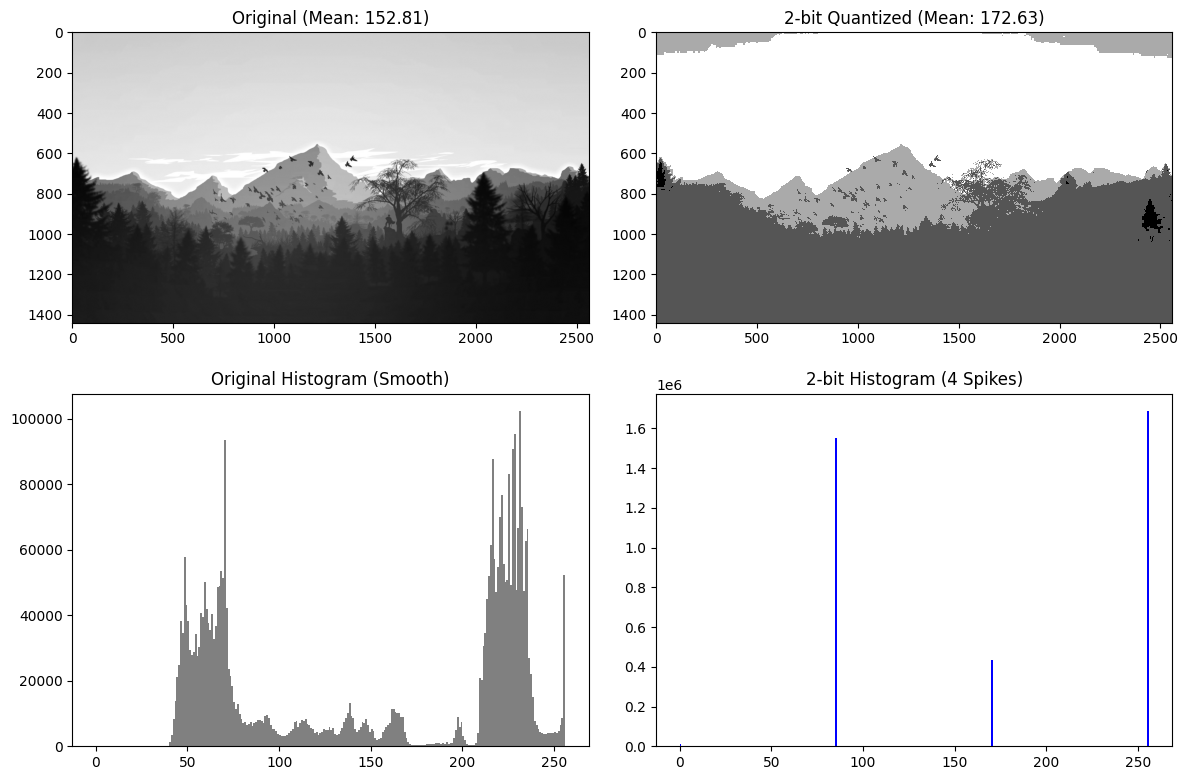

In [115]:
def digitize_and_analyze(image_path, bits):
    L = 2**bits
    # Load original image
    original = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    # Quantization logic
    bins = np.linspace(0, 255, L)
    # Flatten the image to 1D, find nearest bin for each pixel, then reshape
    quantized = np.array([bins[np.abs(bins - val).argmin()] for val in original.ravel()])
    quantized = quantized.reshape(original.shape).astype(np.uint8)

    # Statistical Analysis (Mean)
    mean_orig = np.mean(original)
    mean_quant = np.mean(quantized)

    # Visualization
    fig, axs = plt.subplots(2, 2, figsize=(12, 8))

    # Row 1: Images
    axs[0, 0].imshow(original, cmap='gray')
    axs[0, 0].set_title(f"Original (Mean: {mean_orig:.2f})")
    
    axs[0, 1].imshow(quantized, cmap='gray', interpolation='nearest')
    axs[0, 1].set_title(f"{bits}-bit Quantized (Mean: {mean_quant:.2f})")

    # Row 2: Histograms
    # .ravel() turns the 2D image into a 1D list of pixel values
    axs[1, 0].hist(original.ravel(), bins=256, color='gray', range=[0, 256])
    axs[1, 0].set_title("Original Histogram (Smooth)")

    axs[1, 1].hist(quantized.ravel(), bins=256, color='blue', range=[0, 256])
    axs[1, 1].set_title(f"{bits}-bit Histogram ({L} Spikes)")

    plt.tight_layout()
    plt.show()

# Run for 2-bit depth
digitize_and_analyze(img, bits=2)
